In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
DATA_PATH = r"C:\Users\basma\Downloads\The-Stars-NASA-Space-App-Project\Data\Data_Earth"

print("Folder exists:", os.path.exists(DATA_PATH))
print("Files:", os.listdir(DATA_PATH))

Folder exists: True
Files: ['s01w047.hgt', 's01w047.num', 's01w047.swb']


In [21]:
files_info = []

for filename in os.listdir(DATA_PATH):

    filepath = os.path.join(DATA_PATH, filename)

    if os.path.isfile(filepath):

        file_size = os.path.getsize(filepath)

        files_info.append({
            "File_Name": filename,
            "Extension": os.path.splitext(filename)[1],
            "Size_Bytes": file_size,
            "Size_MB": round(file_size / (1024 ** 2), 3)
        })

files_df = pd.DataFrame(files_info)

files_df

,File_Name,Extension,Size_Bytes,Size_MB
0,s01w047.hgt,.hgt,25934402,24.733
1,s01w047.num,.num,12967201,12.366
2,s01w047.swb,.swb,12967201,12.366


In [22]:
hgt_path = os.path.join(DATA_PATH, "s01w047.hgt")
num_path = os.path.join(DATA_PATH, "s01w047.num")
swb_path = os.path.join(DATA_PATH, "s01w047.swb")

In [23]:
# Read HGT
hgt = np.fromfile(hgt_path, dtype=">i2")

# Read NUM
num = np.fromfile(num_path, dtype=np.uint8)

# Read SWB
swb = np.fromfile(swb_path, dtype=np.uint8)

print("HGT:", hgt.shape)
print("NUM:", num.shape)
print("SWB:", swb.shape)

HGT: (12967201,)
NUM: (12967201,)
SWB: (12967201,)


In [24]:
hgt_df = pd.DataFrame(hgt)
num_df = pd.DataFrame(num)
swb_df = pd.DataFrame(swb)

In [25]:
hgt_df.head()

,0
0,0
1,0
2,0
3,0
4,0


In [26]:
num_df.head()

,0
0,0
1,0
2,0
3,0
4,0


In [27]:
swb_df.head()

,0
0,255
1,255
2,255
3,255
4,255


In [29]:
print(type(hgt))
print(hgt.shape)
print(hgt.ndim)

<class 'numpy.ndarray'>
(12967201,)
1


In [30]:
hgt = hgt.reshape(3601, 3601)

print(hgt.shape)
print(hgt.ndim)

(3601, 3601)
2


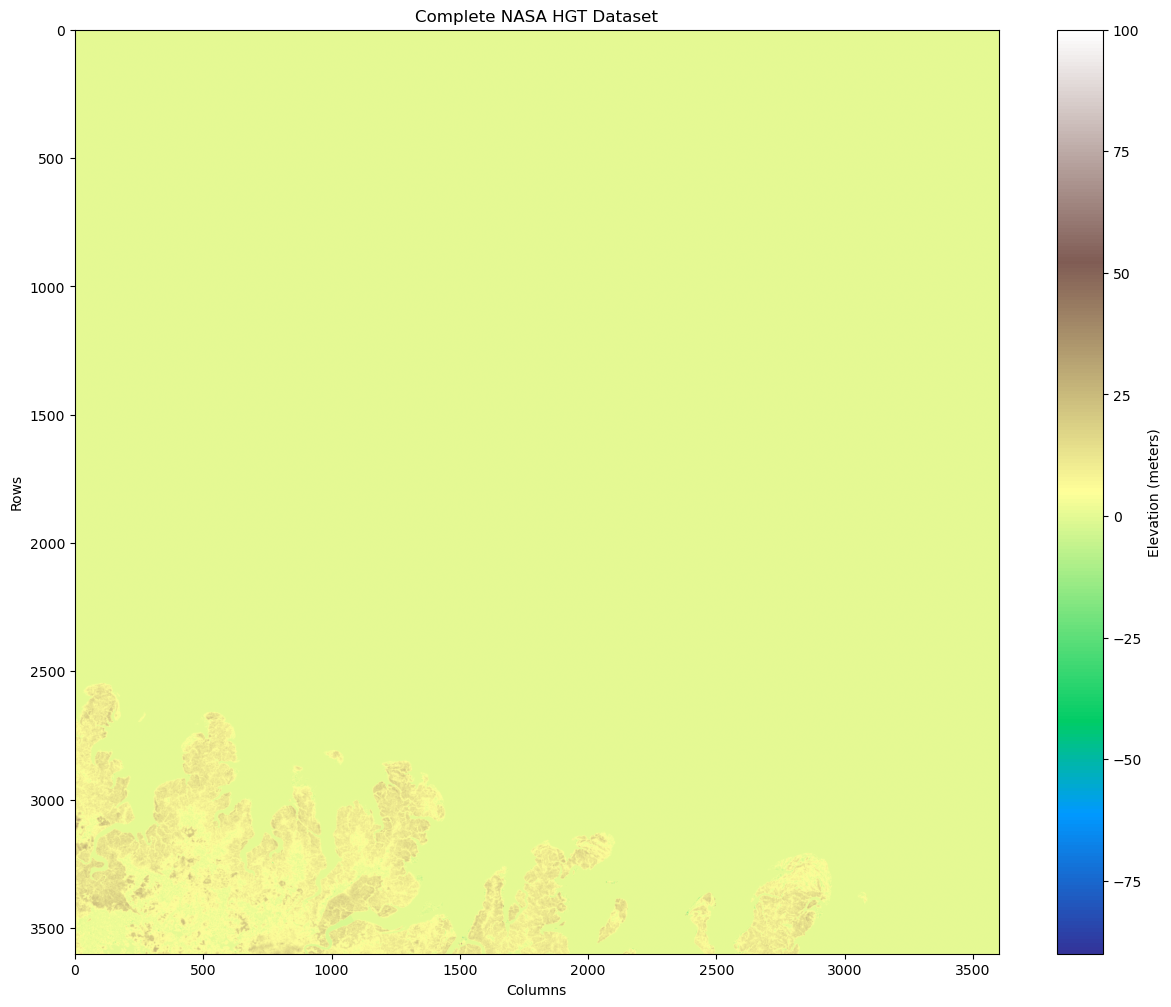

In [31]:
plt.figure(figsize=(15, 12))

plt.imshow(hgt, cmap='terrain')
plt.colorbar(label='Elevation (meters)')

plt.title('Complete NASA HGT Dataset')
plt.xlabel('Columns')
plt.ylabel('Rows')

plt.show()

In [32]:
print("HGT Information")
print("----------------")

print("Shape:", hgt.shape)
print("Data type:", hgt.dtype)

print("First 20 values:")
print(hgt[:20])

print("Minimum:", hgt.min())
print("Maximum:", hgt.max())
print("Mean:", hgt.mean())
print("Median:", np.median(hgt))

HGT Information
----------------
Shape: (3601, 3601)
Data type: >i2
First 20 values:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Minimum: -90
Maximum: 100
Mean: 0.7387407660296158
Median: 0.0


## HGT Dataset – Initial Data Exploration

### 1. Dataset Overview

The HGT file contains elevation-related raster data represented as a 2D NumPy array.

| Attribute | Value | Description |
|---|---:|---|
| Number of Rows | 3,601 | Total number of rows |
| Number of Columns | 3,601 | Total number of columns |
| Total Pixels | 12,967,201 | Total number of data points |
| Data Type | `>i2` | 16-bit signed integer (Big Endian) |
| Minimum Value | -90 | Lowest recorded value |
| Maximum Value | 100 | Highest recorded value |
| Mean | 0.739 | Average of all values |
| Median | 0 | Middle value after sorting all values |

### 2. Understanding the Results

- **Shape (3601 × 3601):** The dataset is organized as a grid containing 3,601 rows and 3,601 columns.
- **Total Pixels:** The grid contains 12,967,201 individual cells, where each cell represents a geographic location.
- **Data Type (`>i2`):** Each value is stored as a 16-bit signed integer using Big Endian byte order.
- **Minimum (-90) and Maximum (100):** These represent the lowest and highest values found in the dataset.
- **Mean (0.739):** The average value across all pixels is approximately 0.739.
- **Median (0):** The middle value of the dataset is zero, indicating that at least half of the observations are less than or equal to zero, and at least half are greater than or equal to zero.

### 3. Initial Observations

1. The dataset contains more than 12.9 million pixels.
2. The values range from -90 to 100.
3. The mean is greater than the median, suggesting that the distribution may be asymmetric.
4. The first displayed values are zeros, which makes it important to investigate how frequently zero occurs.
5. Zero values should not automatically be considered missing values because zero may represent a valid elevation.

`Next Step` ---> `EDA`

**Note:** These are preliminary observations. The physical meaning and units of the values must be verified before drawing geographical conclusions.